# Кейс 3. MindMood - EDA

In [10]:
import numpy as np
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt

**Информация по датасету**

In [11]:
feature_names = ['target', 'id', 'date', 'flag', 'user', 'text']
df = pd.read_csv('./data/Sentiment140.csv', sep=',', encoding='latin-1', names=feature_names)

# Информация по датасету
# print(df.shape)
# print(df.info())
# print(df.describe())
display(df.sample(5))

,target,id,date,flag,user,text
1318346,4,2014361447,Wed Jun 03 01:16:30 PDT 2009,NO_QUERY,nitishupreti,BSNL plan changed...Bye Bye UL Mbps. Nyways I...
1132400,4,1976013199,Sat May 30 16:23:56 PDT 2009,NO_QUERY,claursr,Oh The Joy Of Getting Monster For Free jajaj....
1295574,4,2003745900,Tue Jun 02 07:04:38 PDT 2009,NO_QUERY,breagettingfit,"@ireneisthabomb LOL If I have to go, you have ..."
717230,0,2259933249,Sat Jun 20 18:24:02 PDT 2009,NO_QUERY,cincinyybabe,reallyy misssing friendss text me 643*5136):
795142,0,2327248165,Thu Jun 25 08:06:22 PDT 2009,NO_QUERY,irishspy,@GayPatriot All I see is a picture of Sanford.


Кодирует целевую переменную :
- target = 1 → позитив
- target = 0 → негатив

In [12]:
# Кодирует целевую переменную
# 0 → 0 негатив
# 4 → 1 позитив
df['target'] = df['target'].map({0: 0, 4: 1})

**Баланс классов**

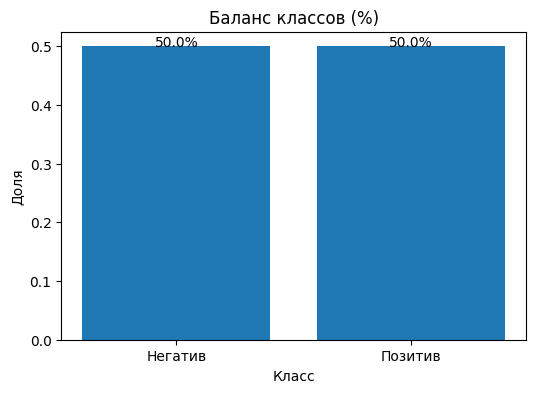

In [13]:
# Строим график баланса классов
labels = ['Негатив', 'Позитив']
counts = df['target'].value_counts(normalize=True).sort_index()

plt.figure(figsize=(6, 4))
plt.bar(labels, counts.values)
plt.title("Баланс классов (%)")
plt.xlabel('Класс')
plt.ylabel('Доля')

# Подписи над столбцами
for i, v in enumerate(counts.values):
    plt.text(i, v, f"{v*100:.1f}%", ha='center')

plt.show()

**Просмотр колонок на уникальные значения**

In [14]:
# Получает категориальные колонки
cat_cols = df.select_dtypes('object').columns

# Посмотрим уникальные значения
for col in cat_cols:
    unique_values = df[col].nunique()
    print(f"Колонка {col} | Уникальных значений: {unique_values}")

Колонка date | Уникальных значений: 774363
Колонка flag | Уникальных значений: 1
Колонка user | Уникальных значений: 659775
Колонка text | Уникальных значений: 1581466


**Удаляет лишние колонки**

In [15]:
# Удаляет лишние данные
df = df.drop(columns=['id', 'flag', 'user'])
display(df.sample(5))

,target,date,text
578432,0,Wed Jun 17 14:53:37 PDT 2009,@randymadlove I have monies &amp; I want you t...
1091811,1,Sat May 30 01:44:36 PDT 2009,@officialnjonas looking forward to evry song l...
953956,1,Sun May 17 02:45:50 PDT 2009,"sunny day today! i'm so happy, tehe."
278883,0,Mon Jun 01 07:24:13 PDT 2009,and it hurts very much.....I am putting off go...
1241929,1,Mon Jun 01 11:26:10 PDT 2009,@olathegis @brisho I had no idea it would work...


**Добавляем фичи по дате**

In [16]:
# копируем DataFrame
df_copy = df.copy()

# Удаляет колонку с тектом
df_copy = df_copy.drop(columns=["text"])

# Чистим дату от timezone
df_copy['date'] = df_copy['date'].str.replace(' PDT', '', regex=False)

# Преобразуем дату из текста в дату
df_copy['date'] = pd.to_datetime(df_copy['date'])

# День недели (название — удобно для графиков)
df_copy['weekday_name'] = df_copy['date'].dt.day_name()

# Является ли выходным
df_copy['weekday'] = df_copy['date'].dt.weekday   # 0 = понедельник
df_copy['is_weekend'] = df_copy['weekday'].isin([5, 6]).astype(int)

# Добавляет информацию в часах и части дня
df_copy['hour'] = df_copy['date'].dt.hour
df_copy['day'] = df_copy['date'].dt.day

# Часть дня
def get_part_of_day(hour):
    if 5 <= hour < 12:
        return 'morning'
    elif 12 <= hour < 18:
        return 'afternoon'
    elif 18 <= hour < 24:
        return 'evening'
    else:
        return 'night'
    
df_copy['part_of_day'] = df_copy['hour'].apply(get_part_of_day)

# Вывод DF с фичами
display(df_copy.sample(5))

,target,date,weekday_name,weekday,is_weekend,hour,day,part_of_day
1453648,1,2009-06-07 01:55:57,Sunday,6,1,1,7,night
1107920,1,2009-05-30 07:35:19,Saturday,5,1,7,30,morning
95990,0,2009-05-13 23:05:57,Wednesday,2,0,23,13,evening
996839,1,2009-05-18 07:05:43,Monday,0,0,7,18,morning
1044948,1,2009-05-29 00:41:40,Friday,4,0,0,29,night


# Анализ влияния временных признаков на настроение (трендовый анализ)

Был проведён анализ зависимости среднего значения целевой переменной (`target`) от различных временных признаков:

- день недели,
- выходной/будний день,
- час публикации,
- день месяца.

Для визуализации использовались:
- столбчатые диаграммы,
- линии тренда поверх графиков.

Линии тренда позволяют лучше увидеть общую тенденцию изменения настроения и сгладить визуальный шум.


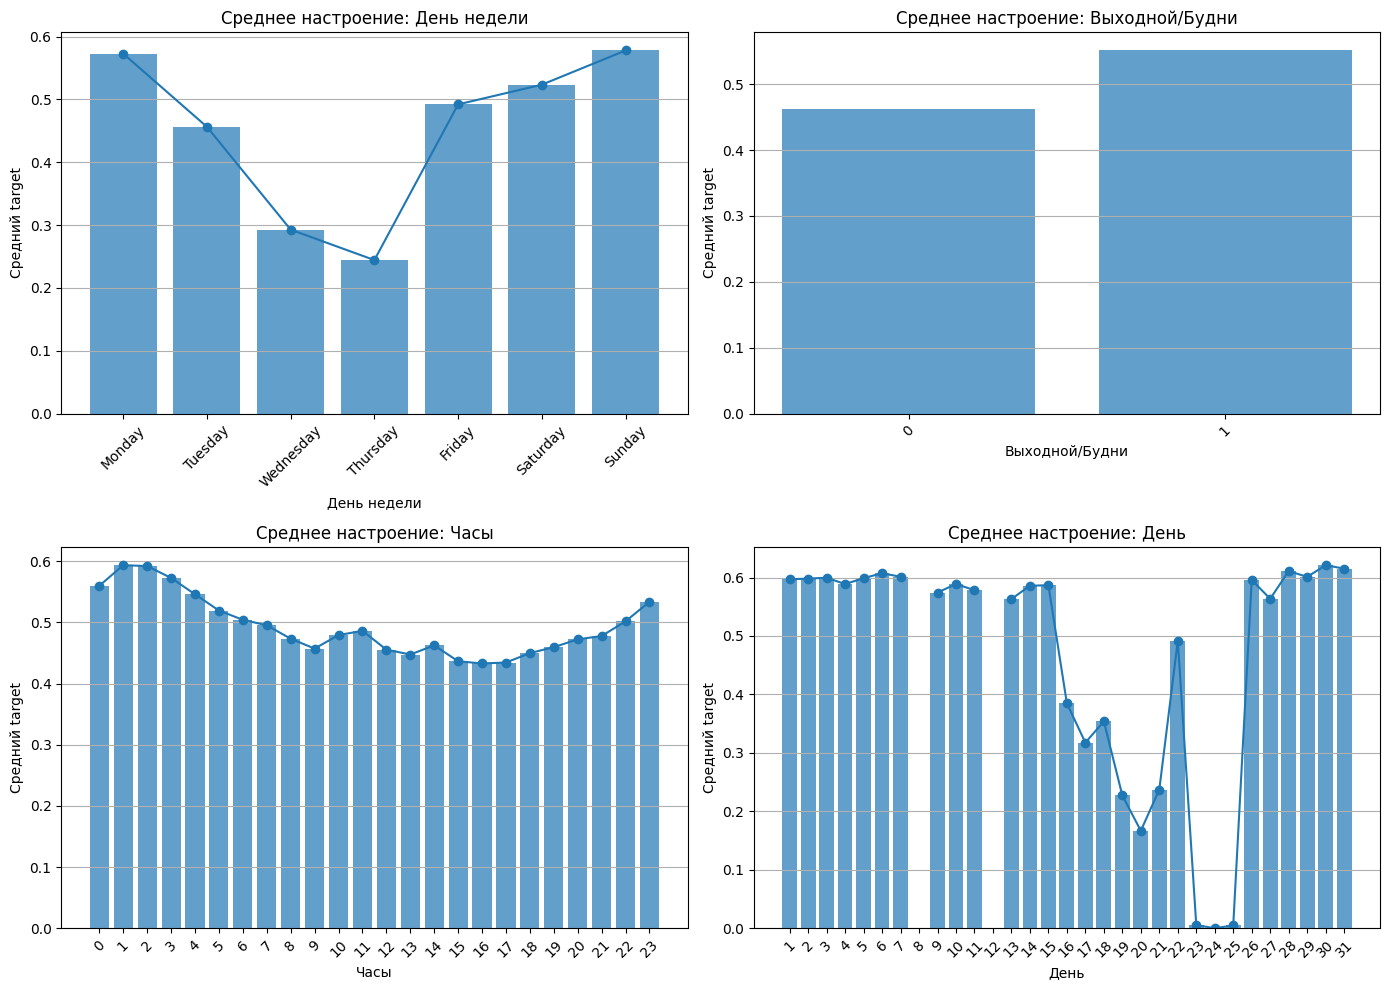

In [17]:
import matplotlib.pyplot as plt
import math

features = [
    ("День недели", "weekday_name"),
    ("Выходной/Будни", "is_weekend"),
    ("Часы", "hour"),
    ("День", "day"),
]

# Порядок категорий
orders = {
    "weekday_name": [
        "Monday",
        "Tuesday",
        "Wednesday",
        "Thursday",
        "Friday",
        "Saturday",
        "Sunday",
    ],

    "is_weekend": [0, 1],

    "hour": list(range(24)),

    "day": list(range(1, 32)),
}

# Количество графиков
count_graphs = len(features)

# 2 колонки
cols = 2

# Автоматически считаем строки
rows = math.ceil(count_graphs / cols)

# Создаем сетку графиков
fig, axes = plt.subplots(rows, cols, figsize=(14, rows * 5))

# Превращаем axes в одномерный массив
axes = axes.flatten()

for i, (feature_name, feature) in enumerate(features):

    df_to_print = (
        df_copy.groupby(feature)["target"]
        .mean()
    )

    # Сортировка данных в человеческом порядоке
    if feature in orders:
        df_to_print = df_to_print.reindex(orders[feature])


    X = df_to_print.index.astype(str)
    y = df_to_print.values

    ax = axes[i]

    ax.bar(X, y, alpha=0.7)
    if feature != "is_weekend":
        ax.plot(X, y, marker='o')

    ax.set_title(f"Среднее настроение: {feature_name}")
    ax.set_xlabel(feature_name)
    ax.set_ylabel("Средний target")

    ax.tick_params(axis='x', rotation=45)
    ax.grid(axis='y')


plt.tight_layout()
plt.show()

## 1. День недели

### Наблюдения

На графике заметны выраженные различия между днями недели:

- самые высокие значения настроения наблюдаются:
  - в воскресенье,
  - в понедельник,
  - в субботу;

- самые низкие:
  - в среду,
  - в четверг.

Также виден тренд:

- настроение постепенно ухудшается к середине недели;
- после четверга снова начинается рост.

### Возможная интерпретация

Это может быть связано с:
- накоплением усталости в рабочие дни;
- психологическим эффектом ожидания выходных;
- более высокой социальной активностью в выходные.

---

## 2. Выходной / будний день

### Наблюдения

Среднее настроение в выходные заметно выше, чем в будние дни.

Разница является достаточно стабильной и визуально хорошо различима.


### Возможная интерпретация

В выходные пользователи:
- меньше подвержены стрессу,
- чаще отдыхают,
- имеют больше свободного времени,
- чаще взаимодействуют с друзьями и семьёй.

---

## 3. Часы суток

### Наблюдения

График показывает плавный суточный цикл настроения:

### Более высокий позитив:
- ночью,
- ранним утром,
- поздним вечером.

### Более низкий:
- днём,
- ближе к рабочему времени.

Минимальные значения наблюдаются примерно:
- с 14 до 18 часов.

После вечера настроение снова начинает расти.

### Возможная интерпретация

Подобный паттерн может быть связан:
- с усталостью в течение рабочего дня,
- высокой нагрузкой днём,
- большей эмоциональной свободой вечером и ночью.

---

## 4. День месяца

### Наблюдения

График показывает нестабильное поведение:

- часть дней имеет высокий уровень позитивности,
- некоторые дни резко падают почти до нуля.

Особенно выделяются:
- 23–25 числа.


### Важное замечание

Такие резкие провалы скорее всего связаны:
- с недостатком данных,
- малым количеством сообщений в отдельные дни,
- шумом выборки.

Поэтому данный признак менее надёжен.

---

## Общий вывод

Графики показывают наличие временных закономерностей в эмоциональном фоне пользователей.

Можно сделать вывод, что:
- настроение зависит от дня недели;
- настроение зависит от времени суток;
- выходные коррелируют с более позитивным эмоциональным состоянием.

Наиболее полезными временными признаками выглядят:
- `hour`,
- `weekday`,
- `is_weekend`.

Признак `day` выглядит менее стабильным из-за сильного шума и возможного дисбаланса данных.

---

# Анализ распределения классов по временным признакам:

Был проведён анализ распределения классов целевой переменной (target) относительно различных временных признаков:

- день недели,
- выходной/будний день,
- час публикации,
- день месяца,
- часть дня.

Цель анализа — определить, как меняется количество положительных и отрицательных записей в зависимости от времени публикации.

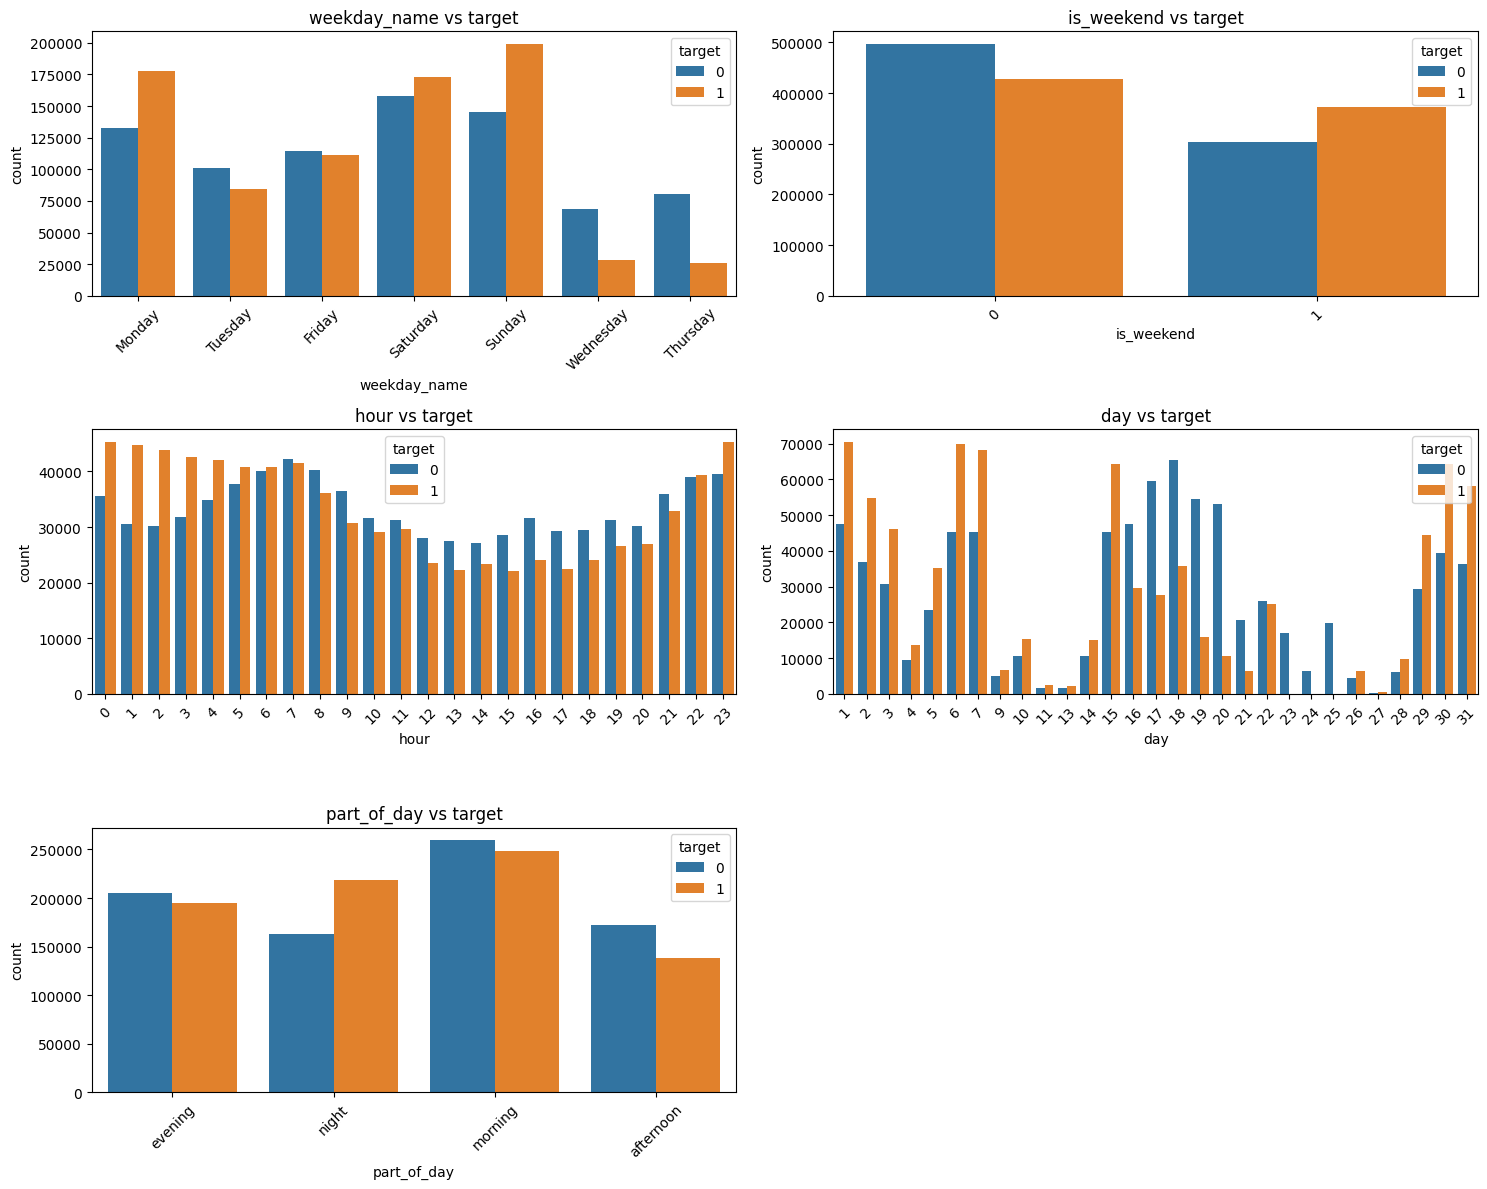

In [18]:
features = [
    "weekday_name",
    "is_weekend",
    "hour",
    "day",
    "part_of_day",
]

cols = 2
rows = int(np.ceil(len(features) / cols))

plt.figure(figsize=(15, 12))

for idx, col in enumerate(features):
    plt.subplot(rows, cols, idx + 1)
    sns.countplot(x=col, hue="target", data=df_copy)

    plt.title(f'{col} vs target')
    plt.xticks(rotation=45)

plt.tight_layout() 
plt.show()

## 1. День недели

График подтверждает ранее найденный тренд:

- в воскресенье, понедельник и субботу количество позитивных сообщений превышает количество негативных;
- в среду и четверг негативных сообщений становится заметно больше.

Особенно сильно различие заметно:
- в воскресенье,
- в четверг,
- в среду.

Это дополнительно подтверждает наличие недельного эмоционального цикла пользователей.

---

## 2. Выходной / будний день

На графике видно:

- в будние дни (`0`) количество негативных сообщений выше;
- в выходные (`1`) позитивные сообщения начинают преобладать.

При этом различие выглядит стабильным и достаточно выраженным.

Это подтверждает гипотезу о том, что выходные положительно влияют на эмоциональное состояние пользователей.

---

## 3. Часы суток

Распределение по часам показывает:

- ночью и поздним вечером позитивных сообщений больше;
- в дневное время количество негативных сообщений возрастает;
- примерно с 12 до 18 часов наблюдается наиболее негативный эмоциональный фон.

Также заметна цикличность:
- вечером эмоциональный фон постепенно улучшается;
- ночью снова увеличивается количество позитивных сообщений.

---

## 4. День месяца

Признак `day` показывает наиболее нестабильное распределение.

На отдельных днях:
- наблюдаются резкие скачки;
- сильно меняется баланс классов;
- присутствуют выбросы.

Вероятнее всего это связано:
- с недостаточным количеством наблюдений;
- дисбалансом данных;
- случайным шумом выборки.

Поэтому данный признак требует осторожного использования в ML-модели.

---

## Вывод по распределению классов

Дополнительно был проведён анализ распределения позитивных (`target = 1`) и негативных (`target = 0`) сообщений относительно временных признаков.

Для этого использовались `countplot`-графики, показывающие количество объектов каждого класса внутри категорий признаков.

Данный анализ позволяет:
- проверить баланс классов;
- оценить достаточность количества наблюдений;
- подтвердить наличие временных закономерностей;
- выявить признаки, потенциально полезные для ML-модели.

---

Анализ распределения позитивных и негативных сообщений подтверждает наличие временных зависимостей в данных.

Наиболее стабильными и информативными признаками выглядят:
- `hour`,
- `weekday_name`,
- `is_weekend`.

Данные признаки:
- имеют устойчивые закономерности;
- содержат различия между позитивными и негативными сообщениями;
- потенциально могут улучшить качество модели классификации.

Признак `day` выглядит менее надёжным из-за высокой нестабильности распределения и возможного шума данных.

---

# Практический вывод для ML-модели

> Эмоциональное состояние определяется не только содержанием текста, но и временем, когда он был написан.


Для задачи определения позитивного и негативного сообщения рекомендуется использовать:

## Основные признаки
- текст сообщения (`TF-IDF`, `Bag of Words`, `Embeddings`);

## Дополнительные признаки
- час публикации;
- день недели;
- выходной/будний день.


Использование временных признаков позволит модели учитывать не только содержание текста, но и поведенческий контекст пользователя, что потенциально может повысить качество классификации.

## Использование в ML-модели

Для повышения качества модели можно использовать комбинированный подход:

```python
X = [TF-IDF(text) + weekday + hour + is_weekend]